In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt 

from tqdm import tqdm
from model import RemappingModel

import utils
torch.set_default_dtype(torch.float64)

In [2]:
import scipy
N = 60

sigma_A = torch.load("./parameters/sigma_A_RoU.pt", weights_only=True)
sigma_B = torch.load("./parameters/sigma_B_RoU.pt", weights_only=True)
sigma_C = torch.load("./parameters/sigma_C_pc.pt",  weights_only=True)

R = utils.random_orthogonal_matrix(len(sigma_A))
p0 = utils.starting_state(R)

A = R.T@sigma_A@R
B = R.T@sigma_B@R
C = R.T@sigma_C@R

model = RemappingModel(A, B, C)
print(f"Number of units: {len(A)}")

Number of units: 120


In [3]:
batch_size = 50 # number of spatial samples
batches = 500
arena_size = 7.5
r_batch = [arena_size*(2*torch.rand((batch_size, 2)).to(torch.float32) - 1) for i in range(batches)] # spatial dataset
r = np.concatenate(r_batch) 

c1 = torch.tensor(0.0, dtype = torch.float32) # fixed context value


In [4]:
# loop over different context values/displacements
context_vals = np.linspace(0, 5, 20)
corrs = []

for c2 in context_vals:
    # package positions with context values
    rc1 = [torch.cat((ri, c1*torch.ones((batch_size,1), dtype = torch.float32)), dim=1) for ri in r_batch]
    rc2 = [torch.cat((ri, c2*torch.ones((batch_size,1), dtype = torch.float32)), dim=1) for ri in r_batch]

    # run model
    p1 = utils.batch_inference(model, rc1, p0)
    p2 = utils.batch_inference(model, rc2, p0)

    # compute and save between-context ratemap similarities
    ratemaps1 = utils.compute_ratemaps(r[:,0], r[:,1], p1, bins = 32)
    ratemaps2 = utils.compute_ratemaps(r[:,0], r[:,1], p2, bins = 32)

    corr = np.sum(ratemaps1*ratemaps2,axis=0)
    corrs.append(corr)  

corr = np.array(corrs)

100%|██████████| 500/500 [00:07<00:00, 70.34it/s]


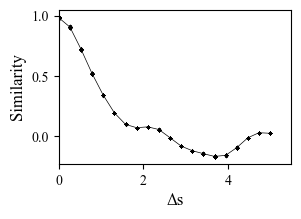

In [5]:
# plot similarity vs context difference
ravelled = corr.reshape((len(context_vals), -1))
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"] 

plt.figure(figsize = (3, 2))
plt.plot(context_vals, np.mean(ravelled, axis = -1), "k", linewidth = 0.5)
for i, c in enumerate(context_vals):
    plt.scatter(c*np.ones(ravelled.shape[-1]), ravelled[i], color = 'k', alpha = 0.1, s = 2)
plt.xlabel("Δs", fontsize = 12)
plt.xlim([0, 5.5])
plt.ylabel("Similarity", fontsize = 12)
plt.savefig("./figures/Remapping_similarity.svg", dpi=300, transparent = True, bbox_inches = "tight")

100%|██████████| 500/500 [00:06<00:00, 79.60it/s]


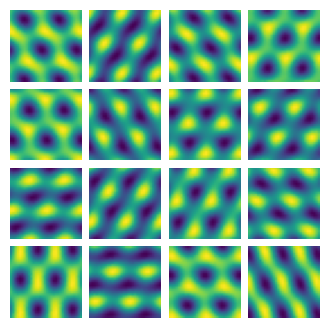

In [8]:
# show two example sets of ratemaps (c1 and c2 = 0, 5)
c1 = torch.tensor(0.0)

rc_batch = [torch.cat((ri, c1*torch.ones((batch_size,1), dtype = torch.float32)), dim=1) for ri in r_batch]
p2 = utils.batch_inference(model, rc_batch, p0)

ratemaps_c1 = utils.compute_ratemaps(r[:,0], r[:,1], p1, bins = 32)
utils.ratemap_collage(ratemaps_c1, 4, 4, figsize=(4,4))
plt.savefig("./figures/ratemap_c1.svg", dpi=300, transparent = True)

100%|██████████| 500/500 [00:06<00:00, 80.89it/s]


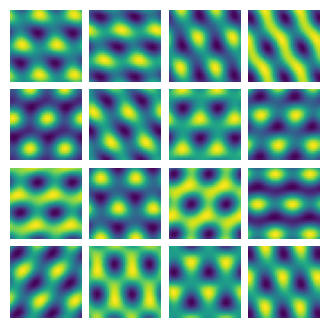

In [9]:
c2 = torch.tensor(5.0)

rc_batch = [torch.cat((ri, c2*torch.ones((batch_size,1), dtype = torch.float32)), dim=1) for ri in r_batch]
p2 = utils.batch_inference(model, rc_batch, p0)

ratemaps_c2 = utils.compute_ratemaps(r[:,0], r[:,1], p2, bins = 32)
utils.ratemap_collage(ratemaps_c2, 4, 4, figsize=(4,4))
plt.savefig("./figures/ratemaps_c2.svg", dpi=300, transparent = True)